# Planning for a bus that drives slower than promised

`safety_factor` inflates the travel estimates the policy tests feasibility
against, so schedules survive a drive that runs slower than predicted. It is
**the one live knob for CARLA** and it has never been swept properly.

The trade is meant to be: a larger factor plans more conservatively, so fewer
riders are picked up later than the service window promised — at the cost of
refusing more requests and lengthening the schedules that remain.

## What "breach" means here

The service window is a **promise, not a guarantee**. `WindowInsertionPolicy`
refuses a request it cannot schedule inside the window, but two things can
still break it: execution runs slower than the estimate, and the progress
fallback drives to the nearest pending pickup when nothing can be scheduled,
ignoring the window entirely.

A **breach** here is a fulfilled request whose actual wait exceeded the window
it was accepted under. It is computed from the stored per-passenger waits, so
it needs no extra instrumentation.

!!! warning "The window must be tighter than patience, or there is nothing to see"
    At `window == patience` a breach is **structurally impossible**: anyone
    who waits past the window has already been cancelled, so no *fulfilled*
    request can breach and the rate is a flat zero. Abandonment enforces the
    promise on the policy's behalf.

    This sweep therefore uses a **750 s window against 900 s patience**,
    leaving a 150 s band in which a broken promise is observable — the same
    setup that measured 2.3% breaches in `window_insertion.md`. The operating
    point recommended elsewhere is W900; the point here is to measure the
    knob, not to re-pick the window.

## What it varies

- **`travel_noise`** — σ of the lognormal factor applied to what the bus
  *actually* drives, while the policy keeps planning against the clean graph.
  σ=0 is the noiseless world every other result uses.
- **`safety_factor`** — 1.0 plans against the raw estimate; 1.5 assumes every
  leg takes half again as long.
- **Three maps**, so the answer is not read off one instance.

## Configuration

In [1]:
from src.experiment.store import DEFAULT_RUNS_DIR

# Hardest, median and easiest of the 25 swept maps, by served fraction.
MAPS = {17: "hardest", 10: "median", 15: "easiest"}
MAP_SHAPE = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0),
                 stop_density=0.5)

NOISE = [0.0, 0.1, 0.2, 0.3]
FACTORS = [1.0, 1.1, 1.25, 1.5]

# The window is deliberately TIGHTER than passenger patience, and the sweep
# is meaningless otherwise. At window == patience, anyone who waits past the
# window has already been cancelled, so no *fulfilled* request can breach and
# the breach rate is structurally zero -- abandonment enforces the promise on
# the policy's behalf. A 750 s window against 900 s patience leaves a 150 s
# band in which a broken promise is observable, and matches the setup that
# measured 2.3% breaches in window_insertion.md.
WINDOW = 750.0
PATIENCE = 900.0
BASE_TRIAL = dict(max_requests=200, capacity=40, demand_interval_s=60.0,
                  max_time=100000.0)
SEEDS = list(range(40))

RUNS = DEFAULT_RUNS_DIR
N_JOBS = 10

In [2]:
import math
import statistics
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler
from scipy import stats

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import run_campaign
from src.experiment.store import load_runs
from src.map.graph import PlanarStreetGraph

from IPython.display import Markdown, display

# Validated palette slots 1-3 (all-pairs CVD 9.2, normal-vision 24.0 on this
# surface). Three is the cap that clears all-pairs; a fourth series folds into
# "Other" or gets a facet of its own.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
PRIMARY = SERIES[0]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})


def mean_of(runs, field):
    """
    Average one KPI over a set of runs.
    :param runs: RunRecords.
    :param field: KPISnapshot attribute name.
    :return: The mean, or NaN when nothing is defined.
    """
    values = [getattr(r.kpi, field) for r in runs
              if getattr(r.kpi, field) is not None]
    return statistics.fmean(values) if values else float("nan")


def half_width(values, confidence=0.95):
    """
    95% confidence half-width for a sample.
    :param values: The sample.
    :param confidence: Confidence level.
    :return: The half-width, or 0.0 when it is undefined.
    """
    if len(values) < 2:
        return 0.0
    return (stats.t.ppf(1 - (1 - confidence) / 2, len(values) - 1)
            * statistics.stdev(values) / len(values) ** 0.5)


def policies_at(factor):
    """
    Build the two leaders at one safety factor.
    :param factor: safety_factor to construct them with.
    :return: (label, factory) pairs.
    """
    return [
        (f"Window W900 s{factor}",
         lambda g, f=factor: WindowInsertionPolicy(
             g, max_wait_s=WINDOW, safety_factor=f)),
        (f"Reordering W900 s{factor}",
         lambda g, f=factor: ReorderingInsertionPolicy(
             g, max_wait_s=WINDOW, safety_factor=f)),
    ]


total = len(MAPS) * len(NOISE) * len(FACTORS) * 2 * len(SEEDS)
print(f"{len(MAPS)} maps x {len(NOISE)} noise levels x {len(FACTORS)} "
      f"factors x 2 policies x {len(SEEDS)} seeds = {total:,} trials")
print()
print("noise_seed is left unset, so it follows the trial seed: demand and "
      "execution luck move together and a (map, seed) pair is one scenario "
      "every arm faces identically.")

3 maps x 4 noise levels x 4 factors x 2 policies x 40 seeds = 3,840 trials

noise_seed is left unset, so it follows the trial seed: demand and execution luck move together and a (map, seed) pair is one scenario every arm faces identically.


## Run it

`travel_noise` perturbs only what the **backend** drives. The policy keeps
planning against the clean graph, which is the whole point — it opens the gap
between what a schedule promises and what the bus delivers, which is the gap
CARLA opens for real.

In [3]:
def world_for(map_seed, noise):
    """
    Describe the map and how unreliable the driving is.

    ``travel_noise`` is a trial parameter and is captured automatically, but
    it is repeated here because it changes the *world* in every sense that
    matters, and a world that did not mention it would read as complete when
    it was not.
    :param map_seed: Seed handed to PlanarStreetGraph.generate.
    :param noise: Sigma of the execution noise.
    :return: The world identity.
    """
    return {
        "map": "planar", "n_seeds": MAP_SHAPE["n_seeds"],
        "bounds": list(MAP_SHAPE["bounds"]),
        "stop_density": MAP_SHAPE["stop_density"],
        "map_seed": map_seed, "backend": "MockBackend",
        "travel_noise": noise,
    }


started = time.perf_counter()
ran = skipped = 0
for map_seed in MAPS:
    graph = PlanarStreetGraph.generate(**MAP_SHAPE, seed=map_seed)
    for noise in NOISE:
        for factor in FACTORS:
            result = run_campaign(
                policies=policies_at(factor), seeds=SEEDS,
                world=world_for(map_seed, noise), directory=RUNS,
                graph=graph, n_jobs=N_JOBS, progress=False,
                max_wait_s=PATIENCE, travel_noise=noise, **BASE_TRIAL)
            ran += result.ran
            skipped += result.skipped
    print(f"  map {map_seed:<3} ran={ran:<6} skipped={skipped:<6} "
          f"{(time.perf_counter() - started) / 60:5.1f} min")
print("done")

  map 17  ran=1280   skipped=0       14.8 min
  map 10  ran=2560   skipped=0       25.2 min
  map 15  ran=3840   skipped=0       30.5 min
done


## Collect, and compute the breach rate

In [4]:
records = [
    r for r in load_runs(RUNS)
    if r.identity.world.get("stop_density") == 0.5
    and r.identity.world.get("map_seed") in MAPS
    and r.identity.world.get("travel_noise") in NOISE
    and r.identity.policy_params.get("safety_factor") in FACTORS
    and r.identity.policy_params.get("max_wait_s") == WINDOW
]

rows = []
for r in records:
    waits = r.wait_times
    rows.append({
        "map": r.identity.world["map_seed"],
        "noise": r.identity.world["travel_noise"],
        "factor": r.identity.policy_params["safety_factor"],
        "family": r.identity.policy_class.replace("InsertionPolicy", ""),
        "seed": r.identity.seed,
        "served": r.kpi.served_fraction * 100,
        "wait": r.kpi.mean_wait_time,
        "ride": r.kpi.mean_ride_time,
        # A fulfilled rider whose wait exceeded the window they were accepted
        # under. The window is a promise the policy plans to keep, not one the
        # simulation enforces.
        "breach": (100.0 * sum(w > WINDOW for w in waits) / len(waits)
                   if waits else float("nan")),
    })
frame = pd.DataFrame(rows)
print(f"{len(frame)} runs")
display(frame.groupby(["noise", "factor"]).size().unstack())

# If nothing ever breaches, the chart below is a flat line at zero and says
# nothing -- which looks like a result and is not one.
breaching = (frame["breach"] > 0).sum()
print()
if breaching == 0:
    print("WARNING: not one run recorded a breach. Check that WINDOW is "
          f"tighter than PATIENCE (currently {WINDOW:.0f} vs {PATIENCE:.0f}); "
          "at window == patience a fulfilled request cannot breach by "
          "construction.")
else:
    print(f"{breaching} of {len(frame)} runs recorded at least one breach "
          f"(max {frame['breach'].max():.1f}% of a run's fulfilled riders)")

3840 runs


factor,1.00,1.10,1.25,1.50
noise,,,,
0.0,240,240,240,240
0.1,240,240,240,240
0.2,240,240,240,240
0.3,240,240,240,240



3713 of 3840 runs recorded at least one breach (max 15.9% of a run's fulfilled riders)


## 1. Does a safety margin buy anything?

Breach rate against noise, one line per safety factor. If the mechanism works
as intended, a higher factor should sit lower on this chart — and the gap
should widen as the driving gets less reliable.

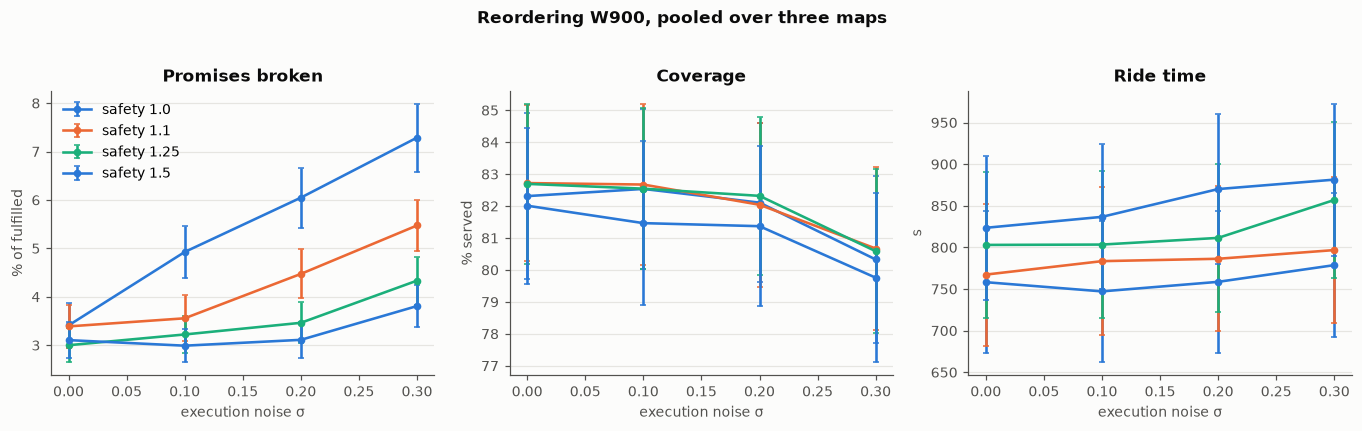

In [5]:
best = frame[frame["family"] == "Reordering"]
figure, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for axis, (metric, title, unit) in zip(axes, [
        ("breach", "Promises broken", "% of fulfilled"),
        ("served", "Coverage", "% served"),
        ("ride", "Ride time", "s")]):
    for factor in FACTORS:
        subset = best[best["factor"] == factor].groupby("noise")[metric]
        means = subset.mean()
        errs = subset.apply(lambda v: half_width(list(v)))
        axis.errorbar(means.index, means.values, yerr=errs.values, marker="o",
                      markersize=4, lw=1.7, capsize=2,
                      label=f"safety {factor}")
    axis.set_title(title)
    axis.set_xlabel("execution noise σ")
    axis.set_ylabel(unit)
    axis.grid(axis="y")
    axis.set_axisbelow(True)
axes[0].legend(title="", loc="upper left")
figure.suptitle("Reordering W900, pooled over three maps", y=1.02,
                fontsize=11, fontweight="bold", color=INK)
figure.tight_layout()
plt.show()

!!! warning "Four series is past the validated cap"
    The categorical palette clears its all-pairs floors at **three** slots;
    the fourth puts yellow and orange together and fails. Here the fourth line
    is unavoidable because the factor is an ordered quantity rather than four
    identities — so read it as a **sequential** encoding, and rely on the
    table below rather than on colour alone if any pair is hard to separate.

In [6]:
pivot = best.groupby(["noise", "factor"])[["breach", "served", "ride"]] \
    .mean().round(2)
display(pivot.unstack("factor"))

breach                   served                         ride          \
factor   1.00  1.10  1.25  1.50   1.00   1.10   1.25   1.50    1.00    1.10   
noise                                                                         
0.0      3.41  3.39  3.00  3.11  82.31  82.72  82.70  82.01  758.26  767.38   
0.1      4.93  3.56  3.22  2.99  82.54  82.68  82.55  81.47  747.21  783.53   
0.2      6.05  4.47  3.46  3.11  82.11  82.04  82.32  81.37  758.69  786.39   
0.3      7.29  5.47  4.33  3.81  80.33  80.67  80.59  79.76  778.76  796.83   

                        
factor    1.25    1.50  
noise                   
0.0     803.04  823.59  
0.1     803.45  836.75  
0.2     811.47  870.14  
0.3     857.03  881.46

## 2. The decision

`safety_factor` is worth raising only if the promises it keeps are worth the
coverage and ride time it costs. The table below prices that explicitly,
against `safety_factor=1.0` at the same noise level.

The design review scores ride time as a graded KPI and does **not** score
breach rate at all, which is what made 1.0 the default. If CARLA's real noise
turns out to sit near the top of this range, that trade is worth revisiting
deliberately rather than inheriting.

In [7]:
lines = ["| σ | factor | breach | Δ breach | Δ served | Δ ride | verdict |",
         "| --- | --- | --- | --- | --- | --- | --- |"]
for noise in NOISE:
    at_noise = best[best["noise"] == noise]
    base = at_noise[at_noise["factor"] == 1.0]
    for factor in FACTORS:
        arm = at_noise[at_noise["factor"] == factor]
        d_breach = arm["breach"].mean() - base["breach"].mean()
        d_served = arm["served"].mean() - base["served"].mean()
        d_ride = arm["ride"].mean() - base["ride"].mean()
        verdict = ("baseline" if factor == 1.0 else
                   ("worth it" if d_breach < -0.5 and d_served > -1.0
                    else "not worth it"))
        lines.append(
            f"| {noise} | {factor} | {arm['breach'].mean():.2f}% | "
            f"{d_breach:+.2f} pp | {d_served:+.2f} pp | {d_ride:+.0f} s | "
            f"{verdict} |")
display(Markdown("\n".join(lines)))

| σ | factor | breach | Δ breach | Δ served | Δ ride | verdict |
| --- | --- | --- | --- | --- | --- | --- |
| 0.0 | 1.0 | 3.41% | +0.00 pp | +0.00 pp | +0 s | baseline |
| 0.0 | 1.1 | 3.39% | -0.02 pp | +0.41 pp | +9 s | not worth it |
| 0.0 | 1.25 | 3.00% | -0.41 pp | +0.38 pp | +45 s | not worth it |
| 0.0 | 1.5 | 3.11% | -0.30 pp | -0.30 pp | +65 s | not worth it |
| 0.1 | 1.0 | 4.93% | +0.00 pp | +0.00 pp | +0 s | baseline |
| 0.1 | 1.1 | 3.56% | -1.37 pp | +0.14 pp | +36 s | worth it |
| 0.1 | 1.25 | 3.22% | -1.70 pp | +0.01 pp | +56 s | worth it |
| 0.1 | 1.5 | 2.99% | -1.94 pp | -1.07 pp | +90 s | not worth it |
| 0.2 | 1.0 | 6.05% | +0.00 pp | +0.00 pp | +0 s | baseline |
| 0.2 | 1.1 | 4.47% | -1.57 pp | -0.07 pp | +28 s | worth it |
| 0.2 | 1.25 | 3.46% | -2.58 pp | +0.21 pp | +53 s | worth it |
| 0.2 | 1.5 | 3.11% | -2.94 pp | -0.74 pp | +111 s | worth it |
| 0.3 | 1.0 | 7.29% | +0.00 pp | +0.00 pp | +0 s | baseline |
| 0.3 | 1.1 | 5.47% | -1.81 pp | +0.34 pp | +18 s | worth it |
| 0.3 | 1.25 | 4.33% | -2.95 pp | +0.26 pp | +78 s | worth it |
| 0.3 | 1.5 | 3.81% | -3.48 pp | -0.57 pp | +103 s | worth it |

## 3. What to conclude

Fill in once run. Three things worth writing down:

- whether a safety margin reduces broken promises **at all** — the mechanism
  is plausible but has never been shown on this map family;
- what it costs in coverage and ride time, since those are the graded KPIs;
- whether the answer changes with noise, which decides if the default should
  be conditional on the world rather than fixed at 1.0.

If the margin buys little even at σ=0.3, then `safety_factor` is a knob that
can be documented as inert and left alone — which is a useful result, and
cheaper than carrying an untested option into the writeup.